# Example preprocessed lesions

Each `.npz` is one BL→FU lesion pair from `src/lesionloc/preprocess.py`:

| key | shape / dtype | meaning |
|---|---|---|
| `bl` | (64,64,64) float16 | baseline patch, centred on the BL lesion, axes (z,y,x), 2 mm/voxel, HU clipped to [-1000,400] → [0,1] |
| `fu` | (64,64,64) float16 | follow-up patch, centred on the search-window centre (registration guess if `has_propagated`, else BL position) |
| `target_mm` | (3,) float32 | true FU lesion position minus FU window centre, **(x,y,z) mm** — the regression target |
| `has_propagated` | bool | whether the window centre came from `cog_propagated` |

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SPACING, SIZE = 2.0, 64
HU_MIN, HU_MAX = -1000.0, 400.0
C = (SIZE - 1) / 2            # centre voxel index (31.5): window centre sits between voxels

files = sorted(Path("../data/example_lesions").glob("*.npz"))
data = {f.stem: {k: v for k, v in np.load(f).items()} for f in files}
list(data)

['006f52e910_1', '01161aaa0b_1']

## 1. Summary and sanity checks

In [2]:
def hu(a):  # back to Hounsfield units
    return a.astype(np.float32) * (HU_MAX - HU_MIN) + HU_MIN

rows = []
for name, d in data.items():
    t = d["target_mm"]
    rows.append(dict(lesion=name, shape=d["bl"].shape, dtype=str(d["bl"].dtype),
                     has_propagated=bool(d["has_propagated"]),
                     target_xyz_mm=np.round(t, 1), target_norm_mm=round(float(np.linalg.norm(t)), 1),
                     bl_mean=round(float(d["bl"].mean()), 3), fu_mean=round(float(d["fu"].mean()), 3)))
for r in rows:
    print(r)

{'lesion': '006f52e910_1', 'shape': (64, 64, 64), 'dtype': 'float16', 'has_propagated': True, 'target_xyz_mm': array([ 18.5,   8.1, -17.1], dtype=float32), 'target_norm_mm': 26.5, 'bl_mean': 0.659, 'fu_mean': 0.658}
{'lesion': '01161aaa0b_1', 'shape': (64, 64, 64), 'dtype': 'float16', 'has_propagated': True, 'target_xyz_mm': array([0.5, 0.9, 1.2], dtype=float32), 'target_norm_mm': 1.6, 'bl_mean': 0.365, 'fu_mean': 0.345}


In [3]:
for name, d in data.items():
    for k in ("bl", "fu"):
        a = d[k].astype(np.float32)
        assert a.shape == (SIZE,) * 3 and 0.0 <= a.min() and a.max() <= 1.0, (name, k)
    # target must lie inside the window with the margin used by preprocess.py
    assert np.abs(d["target_mm"]).max() <= SPACING * SIZE / 2 - 8, name
print("all checks passed")

all checks passed


## 2. Orthogonal views

Row 1: BL through its centre (the lesion is at the patch centre). Row 2: FU through the *true* FU lesion position.
The cyan `+` marks the FU window centre, the red `+` the true FU lesion (`window centre + target_mm`).
Voxel position of the true lesion: `C + target/SPACING`, reordered from (x,y,z) to array order (z,y,x).

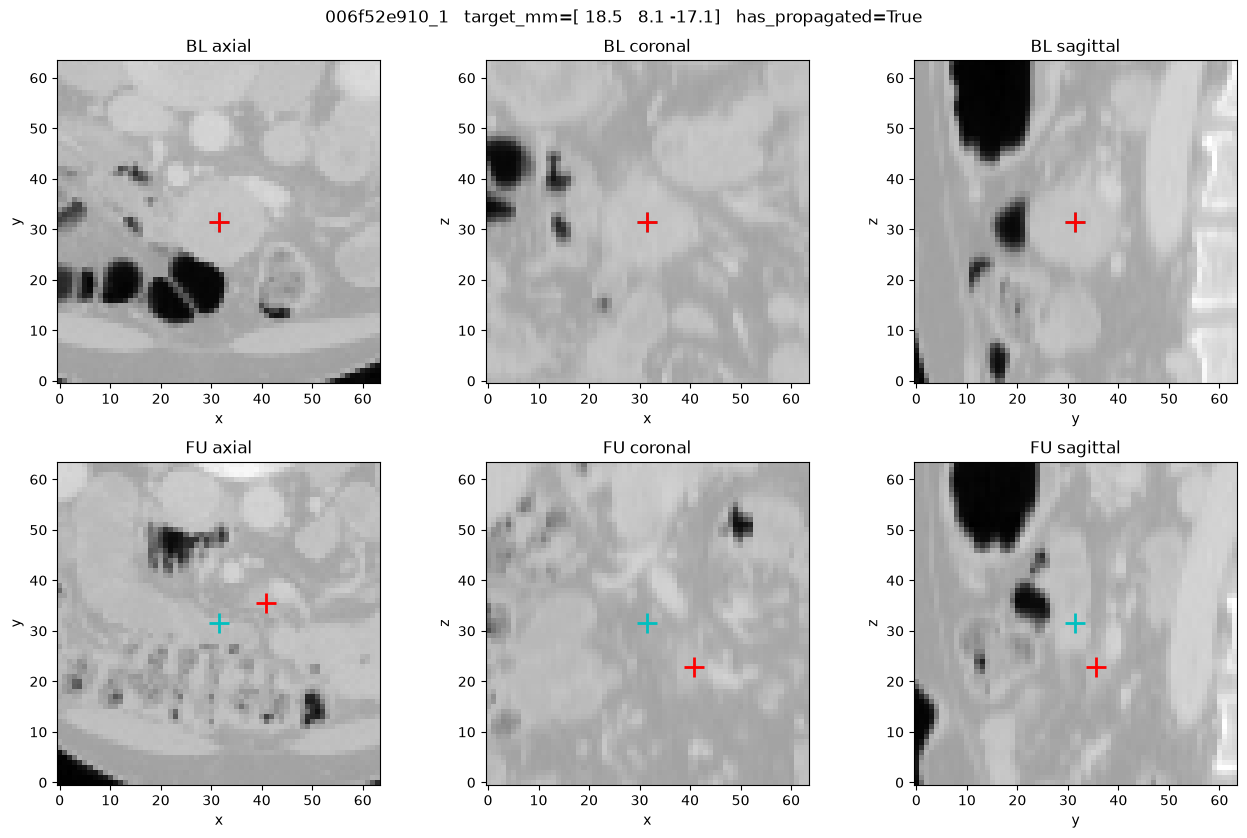

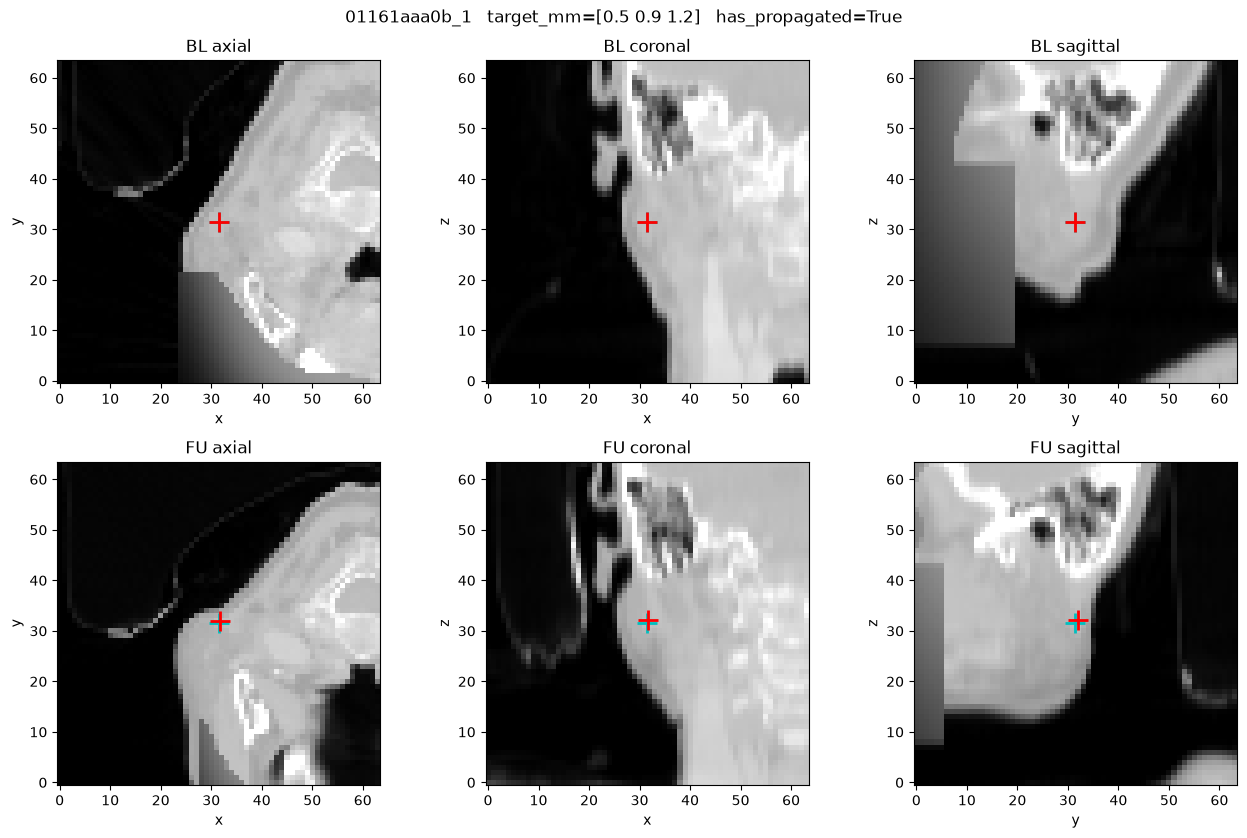

In [4]:
def views(name, d):
    t = d["target_mm"]
    fu_xyz = C + t / SPACING                    # (x,y,z) voxels
    bl_xyz = np.array([C, C, C])
    fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
    for row, (img, p, label) in enumerate([(d["bl"], bl_xyz, "BL"), (d["fu"], fu_xyz, "FU")]):
        x, y, z = p
        zi, yi, xi = (int(round(v)) for v in (z, y, x))
        planes = [(img[zi], (x, y), (C, C), "axial", "x", "y"),
                  (img[:, yi], (x, z), (C, C), "coronal", "x", "z"),
                  (img[:, :, xi], (y, z), (C, C), "sagittal", "y", "z")]
        for col, (sl, pt, ctr, title, a, b) in enumerate(planes):
            ax[row, col].imshow(sl.astype(np.float32), cmap="gray", vmin=0, vmax=1, origin="lower")
            ax[row, col].plot(*ctr, "c+", ms=14, mew=2)
            ax[row, col].plot(*pt, "r+", ms=14, mew=2)
            ax[row, col].set_title(f"{label} {title}")
            ax[row, col].set_xlabel(a); ax[row, col].set_ylabel(b)
    fig.suptitle(f"{name}   target_mm={np.round(t,1)}   has_propagated={bool(d['has_propagated'])}")
    fig.tight_layout()

for name, d in data.items():
    views(name, d)

## 3. Axial slice montage (BL vs FU)

Every 6th axial slice, to see the anatomy around the lesion.

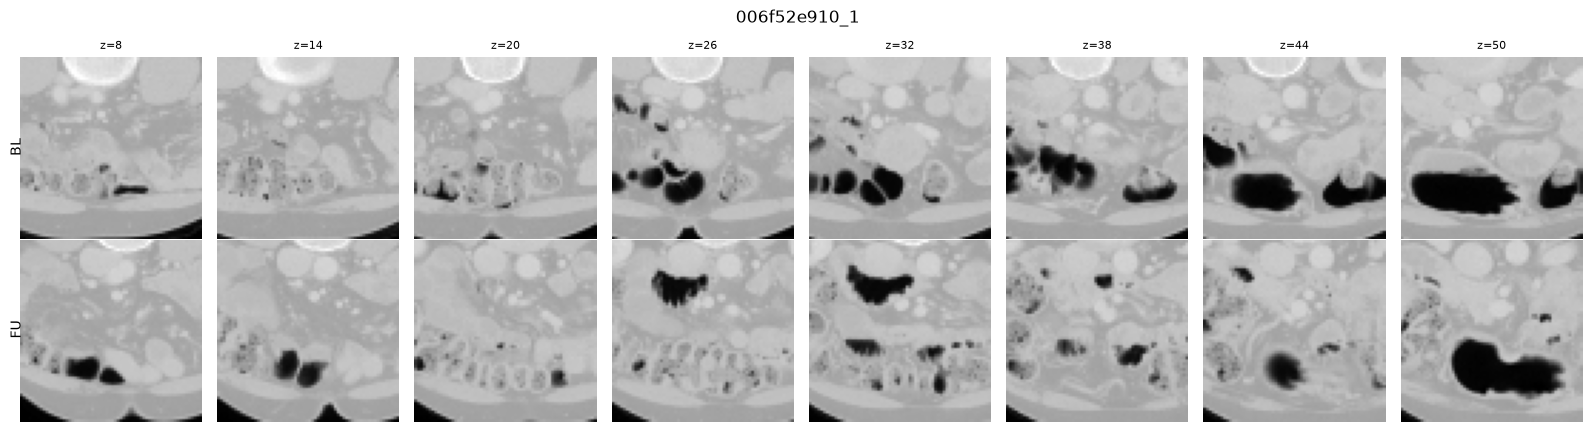

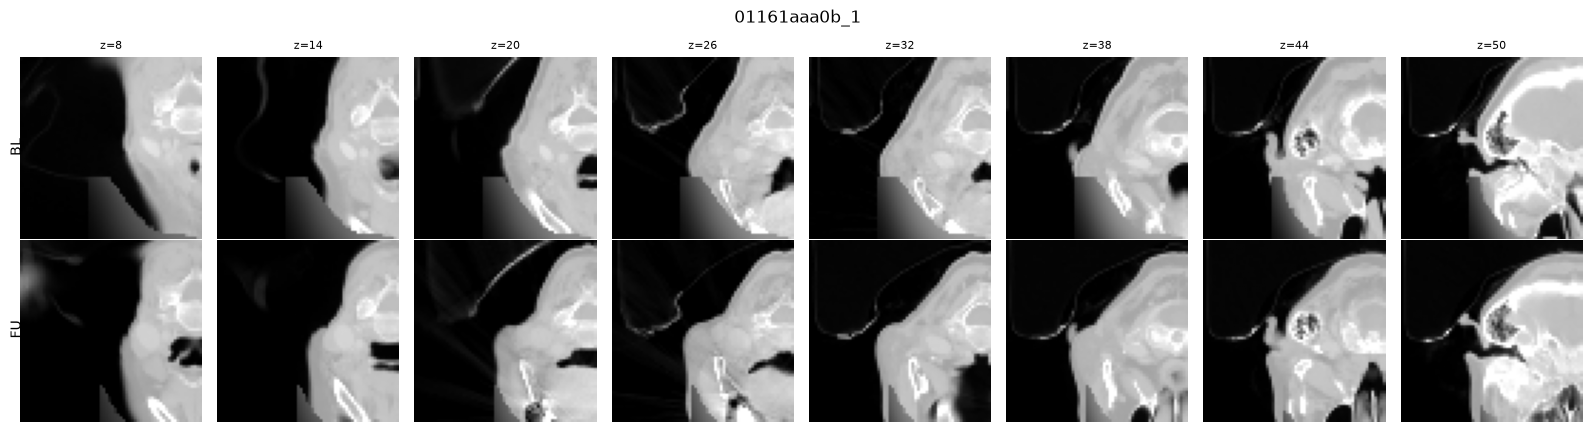

In [5]:
for name, d in data.items():
    zs = list(range(8, 56, 6))
    fig, ax = plt.subplots(2, len(zs), figsize=(2 * len(zs), 4.4))
    for j, z in enumerate(zs):
        for i, k in enumerate(("bl", "fu")):
            ax[i, j].imshow(d[k][z].astype(np.float32), cmap="gray", vmin=0, vmax=1, origin="lower")
            ax[i, j].axis("off")
        ax[0, j].set_title(f"z={z}", fontsize=8)
    ax[0, 0].text(-4, 32, "BL", rotation=90, va="center"); ax[1, 0].text(-4, 32, "FU", rotation=90, va="center")
    fig.suptitle(name); fig.tight_layout()

## 4. Intensity distributions (in HU)

Spikes at -1000 (air/lung or clipped) and -1024→-1000 (padding where the patch left the scan) and at 400 (bone/clipped) are expected.
A large spike at -1000 in a patch means much of it lies outside the scan.

006f52e910_1 fraction of voxels at -1000 HU: {'bl': 0.0, 'fu': 0.001}
01161aaa0b_1 fraction of voxels at -1000 HU: {'bl': 0.124, 'fu': 0.172}


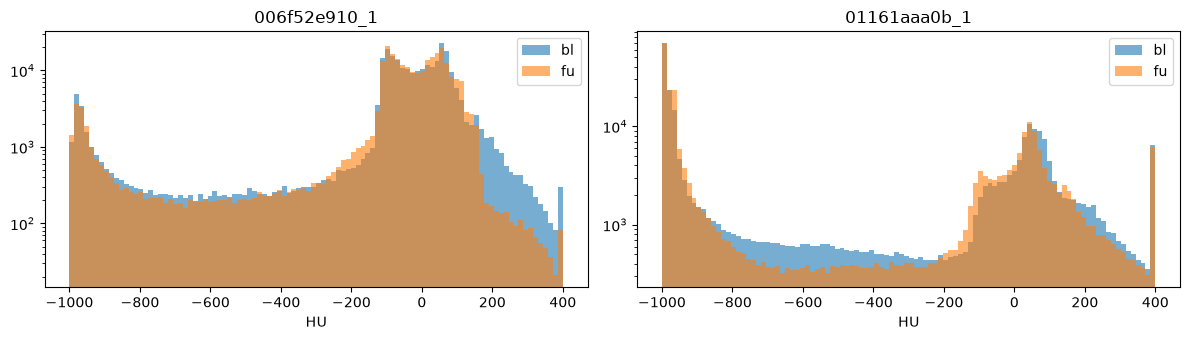

In [6]:
fig, ax = plt.subplots(1, len(data), figsize=(6 * len(data), 3.5), squeeze=False)
for a, (name, d) in zip(ax[0], data.items()):
    for k, c in (("bl", "tab:blue"), ("fu", "tab:orange")):
        a.hist(hu(d[k]).ravel(), bins=100, alpha=.6, label=k, color=c, log=True)
    a.set_title(name); a.set_xlabel("HU"); a.legend()
fig.tight_layout()

for name, d in data.items():
    pad = {k: float((d[k] == 0).mean()) for k in ("bl", "fu")}   # 0.0 == -1000 HU
    print(name, "fraction of voxels at -1000 HU:", {k: round(v, 3) for k, v in pad.items()})

## 5. What the model has to predict

`target_mm` is the offset of the true FU lesion from the FU window centre. If the registration guess were perfect it would be 0.
Large offsets mean the propagated centre was poor (or `has_propagated=False` and the lesion moved a lot).
Preprocessing drops lesions with any |component| > 56 mm.

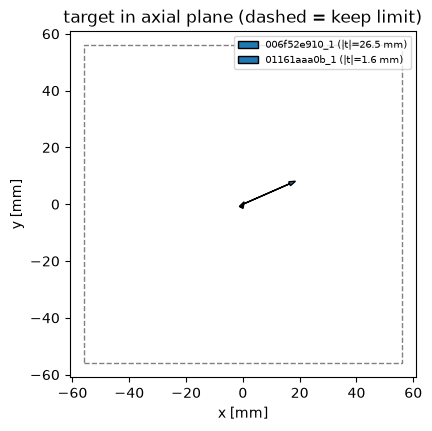

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
lim = SPACING * SIZE / 2 - 8
ax.add_patch(plt.Rectangle((-lim, -lim), 2 * lim, 2 * lim, fill=False, ls="--", color="gray"))
for name, d in data.items():
    ax.arrow(0, 0, d["target_mm"][0], d["target_mm"][1], head_width=1.5, length_includes_head=True,
             label=f"{name} (|t|={np.linalg.norm(d['target_mm']):.1f} mm)")
ax.set_xlim(-lim - 5, lim + 5); ax.set_ylim(-lim - 5, lim + 5); ax.set_aspect("equal")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_title("target in axial plane (dashed = keep limit)")
ax.legend(fontsize=7)

## 6. Does FU look like BL around the centre?

Mean absolute difference between BL and FU patches, and the local intensity at the true FU lesion vs the window centre.
A good sign: intensity at the true lesion position is lesion-like (soft tissue, ~0 to +100 HU → ~0.71–0.79), not air.

In [8]:
def sample(img, xyz):
    x, y, z = (int(round(v)) for v in xyz)
    return float(hu(img)[max(z-1,0):z+2, max(y-1,0):y+2, max(x-1,0):x+2].mean())  # 3^3 mean, HU

for name, d in data.items():
    fu_xyz = C + d["target_mm"] / SPACING
    print(f"{name}: mean|BL-FU|={np.abs(d['bl'].astype(np.float32)-d['fu'].astype(np.float32)).mean():.3f}"
          f"  BL@centre={sample(d['bl'], (C,C,C)):.0f} HU"
          f"  FU@window centre={sample(d['fu'], (C,C,C)):.0f} HU"
          f"  FU@true lesion={sample(d['fu'], fu_xyz):.0f} HU")

006f52e910_1: mean|BL-FU|=0.109  BL@centre=62 HU  FU@window centre=67 HU  FU@true lesion=26 HU
01161aaa0b_1: mean|BL-FU|=0.127  BL@centre=39 HU  FU@window centre=12 HU  FU@true lesion=12 HU
